**Pradeep Manikandan D
24BAD088    Data Science and Visualization Assignemnt-Plotting Techniques**





In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

df = pd.read_csv("happiness_2017.csv")
df.head()


,Country,Region,Rank,HappinessScore,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect,Confidence in national government
0,Norway,Western Europe,1,7.537,7.578745,11.081789,0.950128,71.086586,0.953017,0.210104,0.249711,0.849100,0.202914,0.717160
1,Denmark,Western Europe,2,7.522,7.593702,10.748989,0.952100,71.662498,0.955416,0.145387,0.181148,0.823667,0.205775,0.572353
2,Iceland,Western Europe,3,7.504,7.476214,10.760409,0.966753,72.755981,0.938783,0.235479,0.726845,0.895255,0.148160,0.365042
3,Switzerland,Western Europe,4,7.494,7.473593,10.955548,0.949661,73.173759,0.924997,0.167875,0.316183,0.773997,0.195871,0.819707
4,Finland,Western Europe,5,7.469,7.788252,10.612338,0.963826,71.696960,0.962199,-0.012174,0.192413,0.787137,0.176066,0.597539


In [2]:
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Country                            140 non-null    object 
 1   Region                             140 non-null    object 
 2   Rank                               140 non-null    int64  
 3   HappinessScore                     140 non-null    float64
 4   Life Ladder                        140 non-null    float64
 5   Log GDP per capita                 133 non-null    float64
 6   Social support                     139 non-null    float64
 7   Healthy life expectancy at birth   140 non-null    float64
 8   Freedom to make life choices       139 non-null    float64
 9   Generosity                         132 non-null    float64
 10  Perceptions of corruption          128 non-null    float64
 11  Positive affect                    139 non-null    float64

,Rank,HappinessScore,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect,Confidence in national government
count,140.0000,140.000000,140.000000,133.000000,139.000000,140.000000,139.000000,132.000000,128.000000,139.000000,139.000000,127.000000
mean,70.5000,5.398907,5.491702,9.345615,0.806711,63.440981,0.777874,-0.011614,0.735870,0.699412,0.291164,0.493701
std,40.5586,1.109750,1.122178,1.184935,0.121117,7.595597,0.127969,0.161064,0.179799,0.107246,0.091985,0.198235
min,1.0000,2.693000,2.661718,6.625341,0.319589,44.386528,0.427011,-0.296735,0.161791,0.420962,0.114123,0.110937
25%,35.7500,4.542500,4.636694,8.545789,0.736748,58.005130,0.711635,-0.141405,0.681880,0.614203,0.219028,0.333884
50%,70.5000,5.302000,5.586507,9.547693,0.828953,65.209110,0.811671,-0.035203,0.782116,0.710230,0.280323,0.473544
75%,105.2500,6.212000,6.278276,10.313942,0.905827,69.062944,0.878373,0.098457,0.857171,0.788236,0.345125,0.617711
max,140.0000,7.537000,7.788252,11.465231,0.966753,76.536362,0.985178,0.628706,0.954393,0.895255,0.599335,0.964690


In [3]:
df.isnull().sum()

Country                               0
Region                                0
Rank                                  0
HappinessScore                        0
Life Ladder                           0
Log GDP per capita                    7
Social support                        1
Healthy life expectancy at birth      0
Freedom to make life choices          1
Generosity                            8
Perceptions of corruption            12
Positive affect                       1
Negative affect                       1
Confidence in national government    13
dtype: int64

In [4]:
threshold = len(df) * 0.5
df = df.dropna(thresh=threshold, axis=1)


In [5]:
# Numerical columns → mean
num_cols = df.select_dtypes(include=np.number).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

# Categorical columns → mode
cat_cols = df.select_dtypes(include="object").columns
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])


In [6]:
df.drop_duplicates(inplace=True)


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Rank,140.0,70.500000,40.558600,1.000000,35.750000,70.500000,105.250000,140.000000
HappinessScore,140.0,5.398907,1.109750,2.693000,4.542500,5.302000,6.212000,7.537000
Life Ladder,140.0,5.491702,1.122178,2.661718,4.636694,5.586507,6.278276,7.788252
Log GDP per capita,140.0,9.345615,1.154714,6.625341,8.571481,9.491220,10.283454,11.465231
Social support,140.0,0.806711,0.120681,0.319589,0.738352,0.828646,0.905631,0.966753
Healthy life expectancy at birth,140.0,63.440981,7.595597,44.386528,58.005130,65.209110,69.062944,76.536362
Freedom to make life choices,140.0,0.777874,0.127508,0.427011,0.712146,0.811036,0.877995,0.985178
Generosity,140.0,-0.011614,0.156360,-0.296735,-0.133880,-0.027287,0.089317,0.628706
Perceptions of corruption,140.0,0.735870,0.171863,0.161791,0.708318,0.768706,0.851269,0.954393
Positive affect,140.0,0.699412,0.106860,0.420962,0.614210,0.707354,0.788128,0.895255


In [8]:
num_df = df.select_dtypes(include=np.number)
num_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Rank,140.0,70.500000,40.558600,1.000000,35.750000,70.500000,105.250000,140.000000
HappinessScore,140.0,5.398907,1.109750,2.693000,4.542500,5.302000,6.212000,7.537000
Life Ladder,140.0,5.491702,1.122178,2.661718,4.636694,5.586507,6.278276,7.788252
Log GDP per capita,140.0,9.345615,1.154714,6.625341,8.571481,9.491220,10.283454,11.465231
Social support,140.0,0.806711,0.120681,0.319589,0.738352,0.828646,0.905631,0.966753
Healthy life expectancy at birth,140.0,63.440981,7.595597,44.386528,58.005130,65.209110,69.062944,76.536362
Freedom to make life choices,140.0,0.777874,0.127508,0.427011,0.712146,0.811036,0.877995,0.985178
Generosity,140.0,-0.011614,0.156360,-0.296735,-0.133880,-0.027287,0.089317,0.628706
Perceptions of corruption,140.0,0.735870,0.171863,0.161791,0.708318,0.768706,0.851269,0.954393
Positive affect,140.0,0.699412,0.106860,0.420962,0.614210,0.707354,0.788128,0.895255


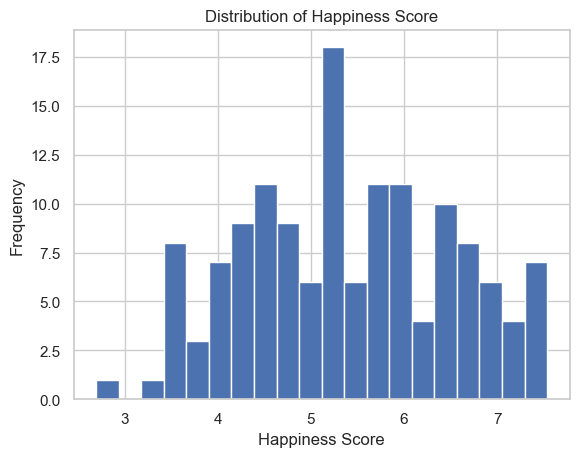

In [9]:
plt.figure()
num_df['HappinessScore'].hist(bins=20)
plt.xlabel("Happiness Score")
plt.ylabel("Frequency")
plt.title("Distribution of Happiness Score")
plt.show()

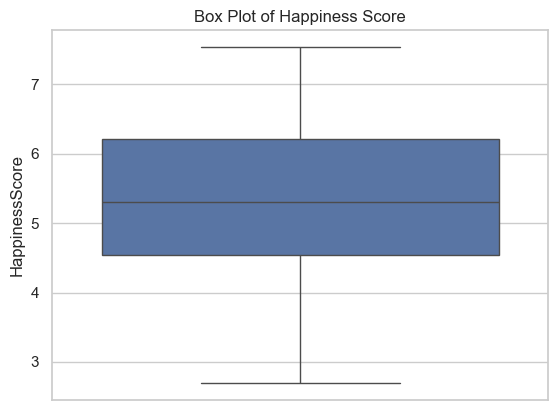

In [10]:
plt.figure()
sns.boxplot(y=num_df['HappinessScore'])
plt.title("Box Plot of Happiness Score")
plt.show()

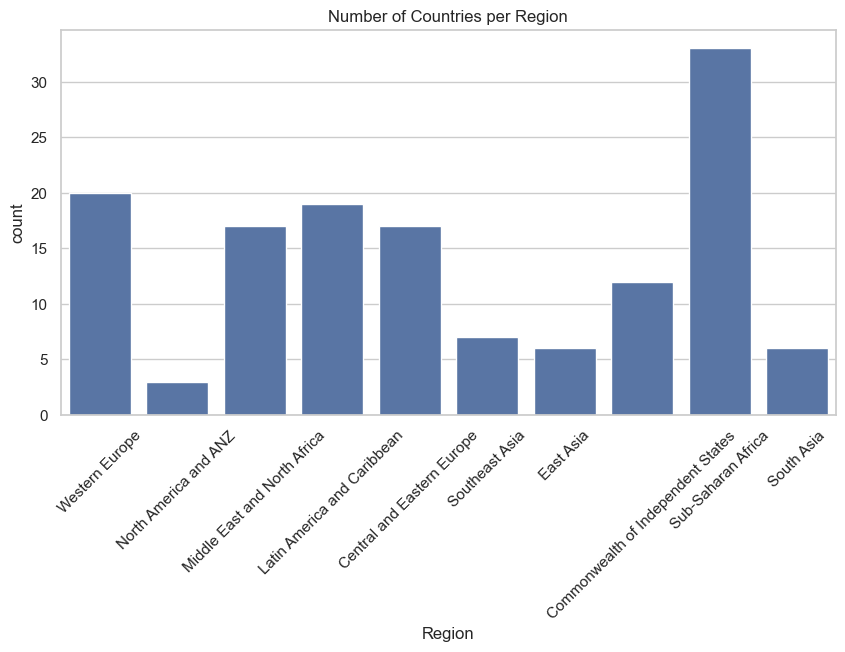

In [11]:
plt.figure(figsize=(10,5))
sns.countplot(x='Region', data=df)
plt.xticks(rotation=45)
plt.title("Number of Countries per Region")
plt.show()


In [ ]:
# Bivariate analysis....

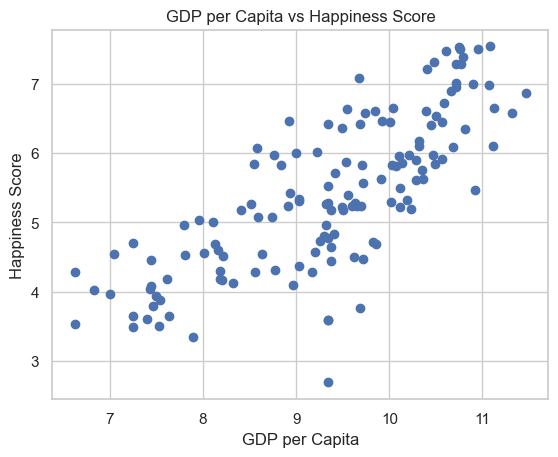

In [12]:
plt.figure()
plt.scatter(
    num_df['Log GDP per capita'],
    num_df['HappinessScore']
)
plt.xlabel("GDP per Capita")
plt.ylabel("Happiness Score")
plt.title("GDP per Capita vs Happiness Score")
plt.show()


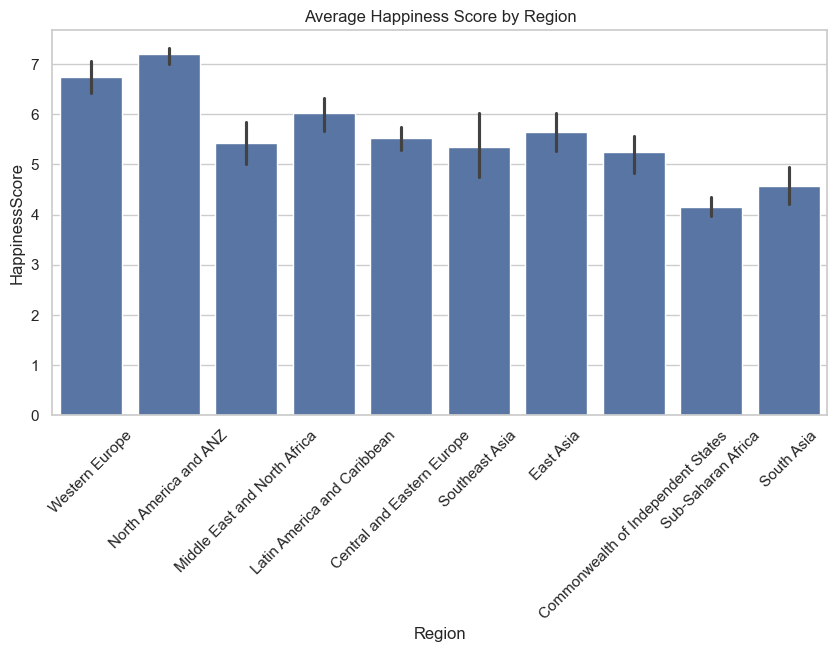

In [13]:
plt.figure(figsize=(10,5))
sns.barplot(
    x='Region',
    y='HappinessScore',
    data=df
)
plt.xticks(rotation=45)
plt.title("Average Happiness Score by Region")
plt.show()

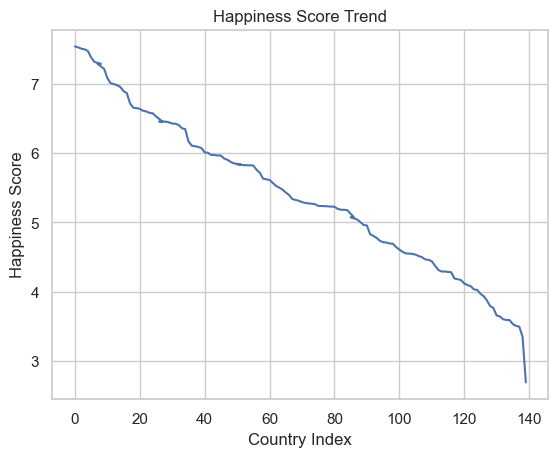

In [14]:
sorted_df = df.sort_values(by='HappinessScore')

plt.figure()
plt.plot(sorted_df['HappinessScore'])
plt.xlabel("Country Index")
plt.ylabel("Happiness Score")
plt.title("Happiness Score Trend")
plt.show()

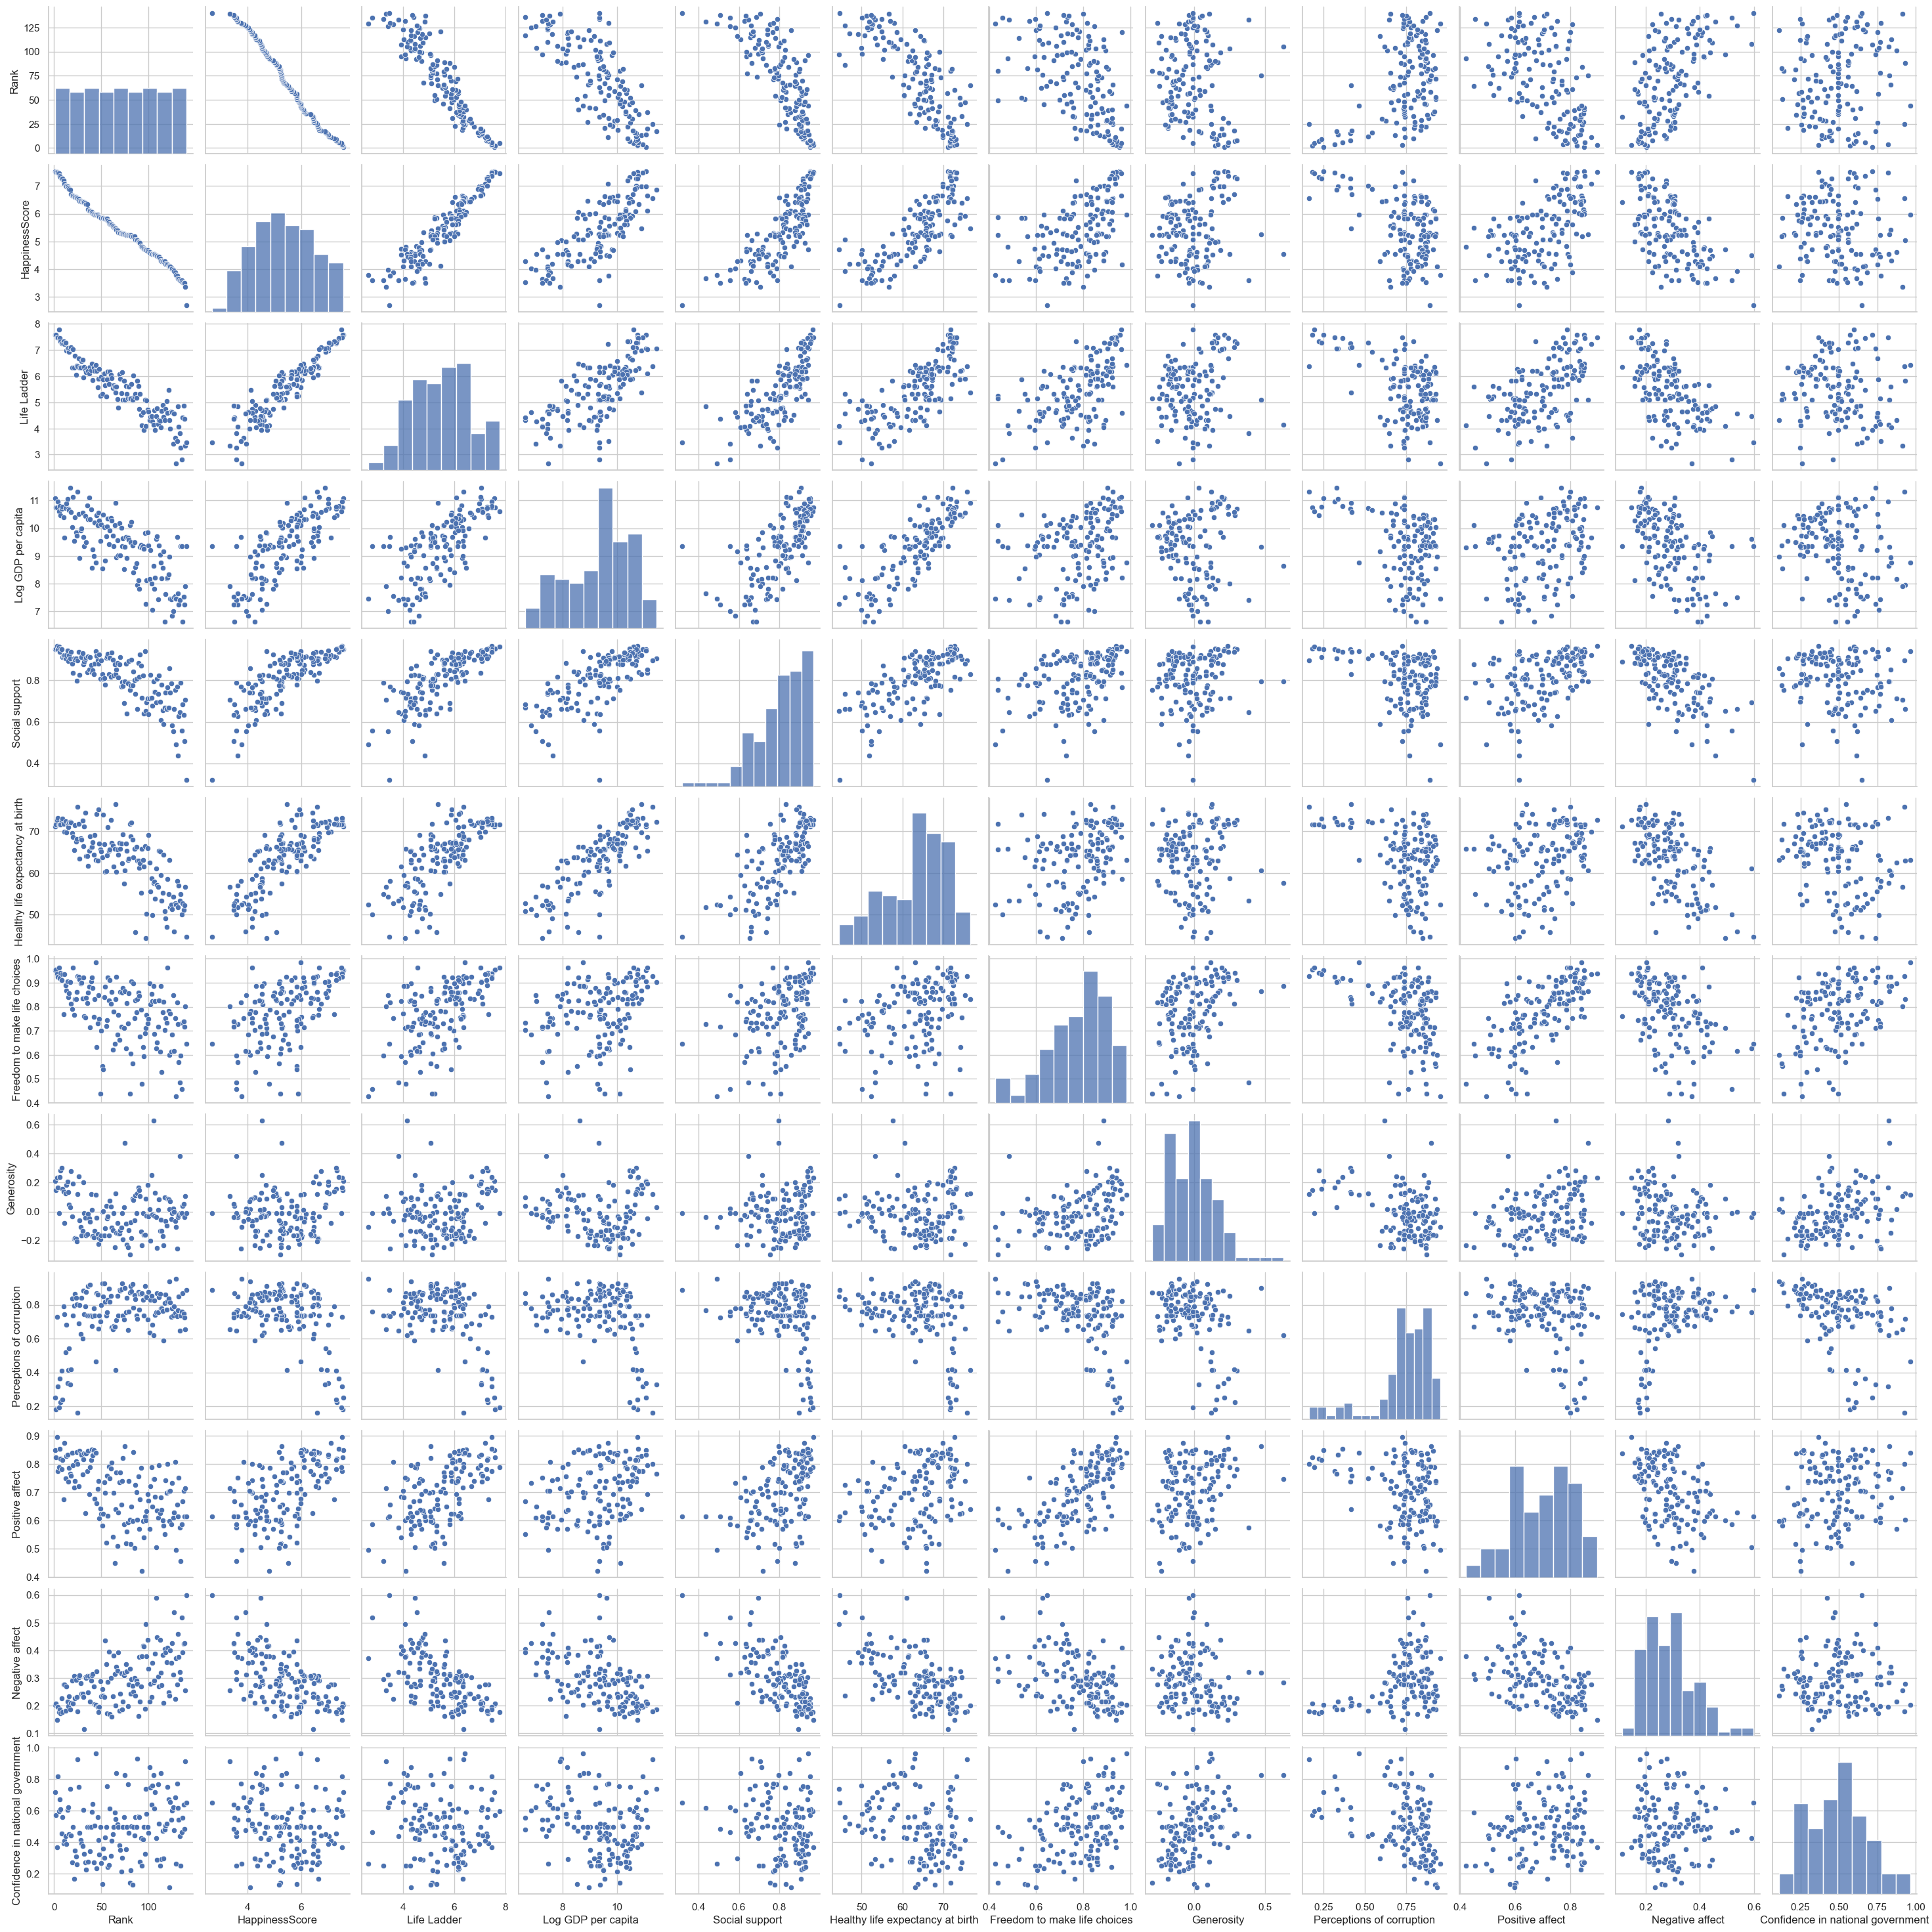

In [15]:
sns.pairplot(num_df)
plt.show()


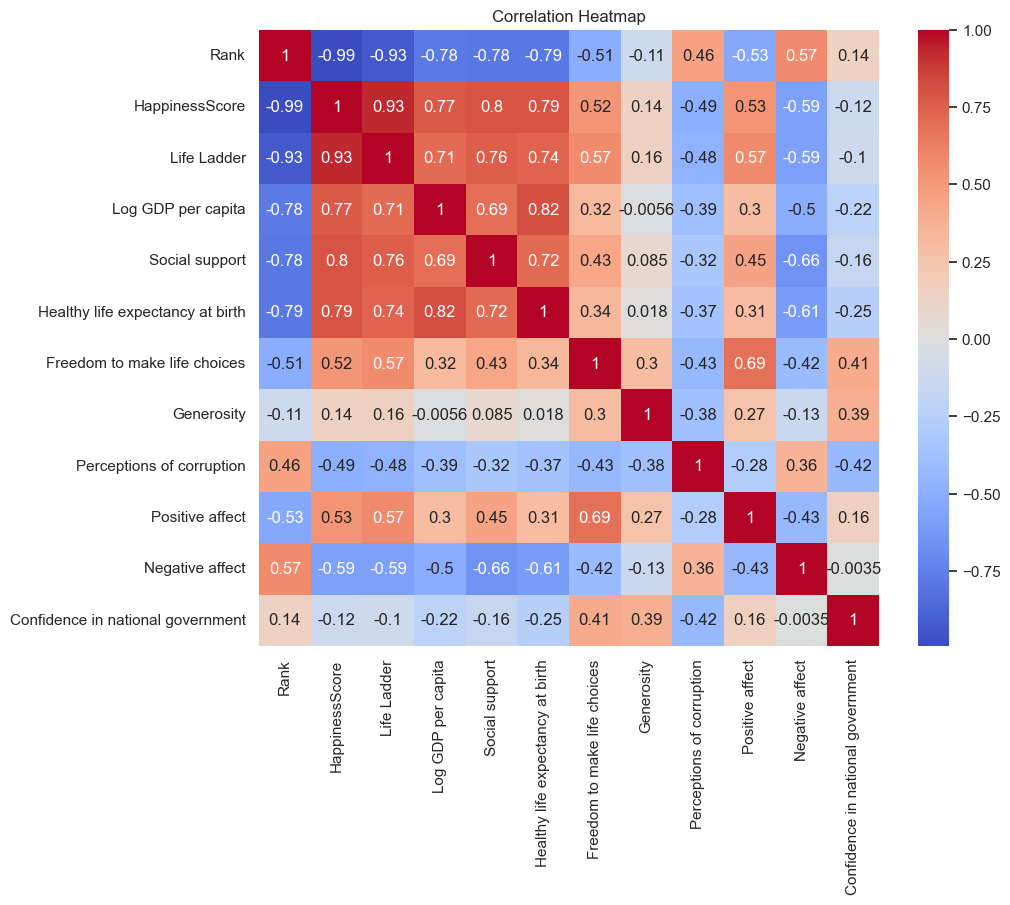

In [16]:
plt.figure(figsize=(10,8))
sns.heatmap(
    num_df.corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()


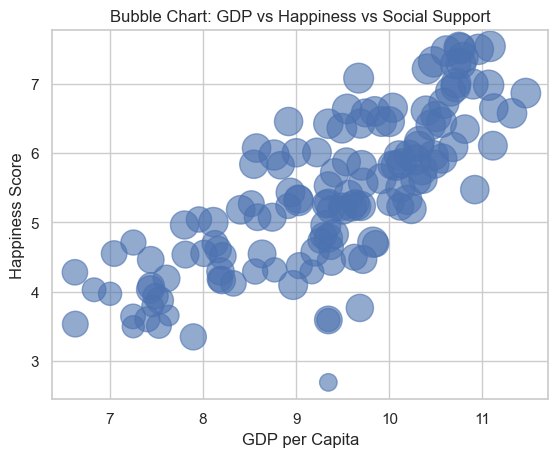

In [17]:
plt.figure()
plt.scatter(
    num_df['Log GDP per capita'],
    num_df['HappinessScore'],
    s=num_df['Social support']*500,
    alpha=0.6
)
plt.xlabel("GDP per Capita")
plt.ylabel("Happiness Score")
plt.title("Bubble Chart: GDP vs Happiness vs Social Support")
plt.show()

In [18]:
df.to_csv("cleaned_happiness_2017.csv", index=False)
